In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

In [3]:
results_df = pd.read_csv('./results/remote/r_id_baseline_rep_100.csv')
results_df.head()
results_df['ESS_(%)'] = (results_df['AvgESS']/results_df['N'])*100

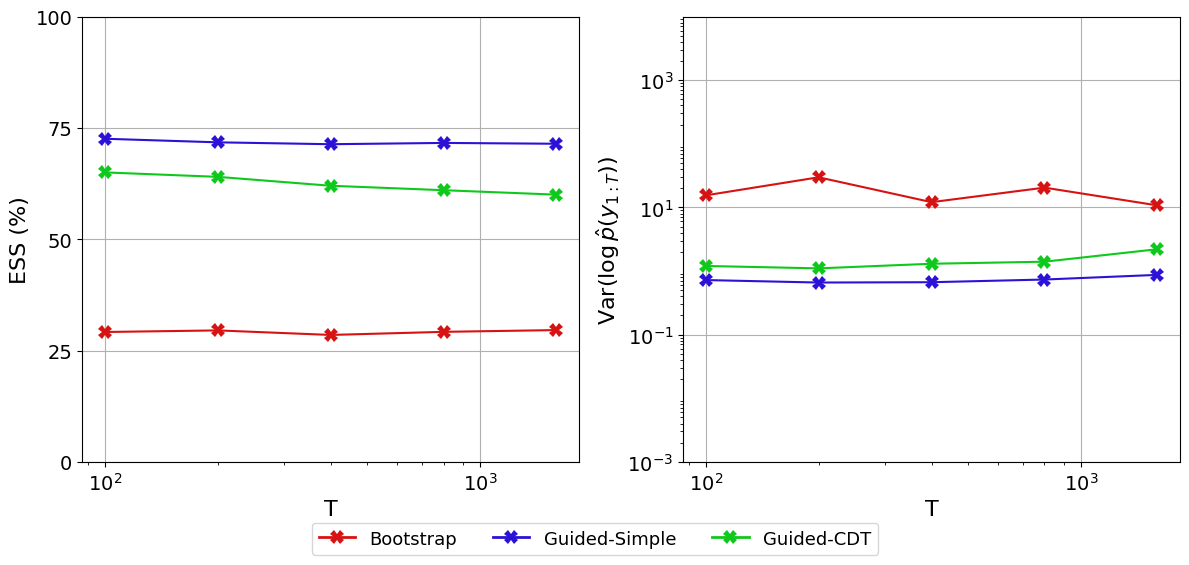

In [4]:
plot_df = results_df.copy()
plot_df['fk'] = plot_df['fk'].map({'bootstrap': 'Bootstrap', 'guided': 'Guided-Simple'})

palette = {"Bootstrap": "#d71212", "Guided-Simple": "#2c12d7"}

line_kwargs = {
    "marker": "X",
    "markersize": 10,
    "markerfacecolor": "auto",
    "markeredgecolor": "none",
    "markeredgewidth": 0,
}
legend_y = 0.05  # Increase this value to move the legend closer to the subplots.

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.lineplot(x='T', y='ESS_(%)', hue='fk', data=plot_df, ax=axes[0], palette=palette, legend=False, errorbar=None, **line_kwargs)
sns.lineplot(x='T', y='LogLt', hue='fk', data=plot_df, ax=axes[1],
             estimator=lambda x: x.var(ddof=1), palette=palette, legend=False, errorbar=None, **line_kwargs)

Ts = np.array([100, 200, 400, 800, 1600])
cdt_ess_values = np.array([65., 64., 62., 61., 60.])
cdt_var_values = np.array([1.2, 1.1, 1.3, 1.4, 2.2])

axes[0].plot(Ts, cdt_ess_values, color="#0ec91b", **line_kwargs)
axes[1].plot(Ts, cdt_var_values, color="#0ec91b", **line_kwargs)

for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('T', fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid()

axes[0].set_ylabel("ESS (%)", fontsize=16)
axes[1].set_ylabel(r"$\mathrm{Var}(\log \hat{p}(y_{1:T}))$", fontsize=16)

axes[0].set_ylim((0, 100))
axes[0].set_yticks([0, 25, 50, 75, 100])

axes[1].set_yscale("log")
axes[1].set_ylim((10**-3, 10 ** 4))
axes[1].set_yticks([10**-3, 10**-1, 10**1, 10**3])

legend_handles = [Line2D([0], [0], color=color, lw=2, label=label, **line_kwargs)
                  for label, color in palette.items()]
legend_handles.append(Line2D([0], [0], color="#0ec91b", lw=2, label="Guided-CDT", **line_kwargs))

fig.legend(handles=legend_handles, loc='lower center', ncol=len(legend_handles),
           fontsize=13, bbox_to_anchor=(0.5, legend_y))
fig.tight_layout(rect=(0, 0.10, 1, 1))

plt.savefig("./figures/fig_10_ess_var_results.pdf", dpi=300, bbox_inches="tight", pad_inches=0.03)